# Track 2 (Explainability & Analysis)
**W1-3: CNN internals + prediction investigation**

Baseline model: the Track 1 Keras CNN on the 6 CIFAR-10 animal classes (bird, cat, deer, dog, frog, horse). Test accuracy: **67.08%**.

- [ ] Read the PyTorch 60-Minute Blitz (tensors, autograd, neural networks, training a CIFAR-10 classifier)
- [x] Show 5 correct + 5 incorrect predictions
- [x] Write observation on failure patterns

## 5 correct vs 5 incorrect predictions

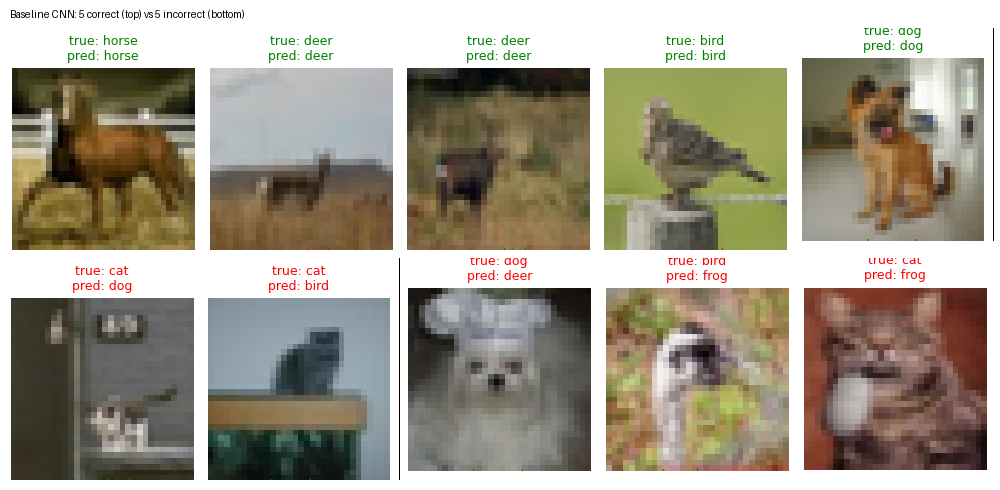

In [ ]:
# figure saved from the Track 1 notebook (Sections 13-14)

| | Image | True → predicted |
|---|---|---|
| Correct | Brown horse on a field | horse → horse |
| Correct | Small deer against a grey sky | deer → deer |
| Correct | Deer in dry grass | deer → deer |
| Correct | Bird on a post, green background | bird → bird |
| Correct | Tan dog indoors, clear pose | dog → dog |
| Wrong | Cat tucked in a dark corner, partly hidden | cat → dog |
| Wrong | Dark grey cat on a bluish background | cat → bird |
| Wrong | Fluffy white dog, blurry, dark background | dog → deer |
| Wrong | Bird head close-up, mottled green background | bird → frog |
| Wrong | Cat close-up, red wall, face partly cropped | cat → frog |

These come from the random 18-image sample in Section 14 of the notebook. `correct_vs_wrong.py` is a cell that picks a fresh set (change the seed) and also prints the top true→predicted error pairs and mean confidence.

## Confusion matrix

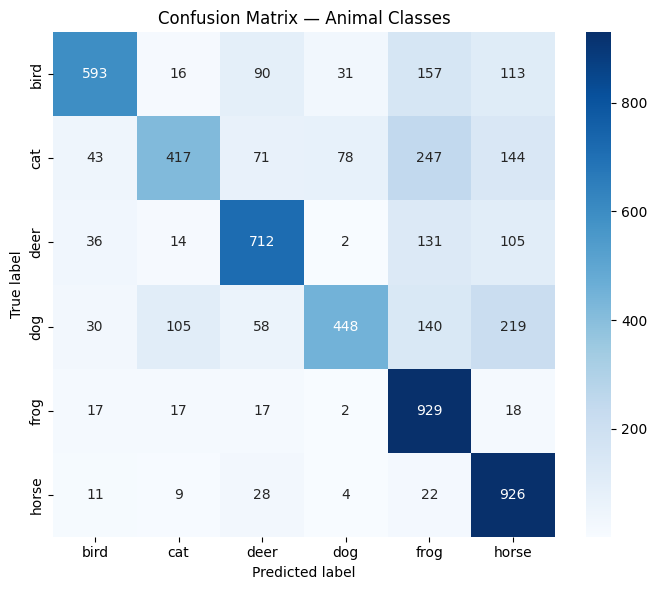

In [ ]:
# figure saved from the Track 1 notebook (Sections 13-14)

| Class | Precision | Recall |
|---|---|---|
| bird | 0.81 | 0.59 |
| cat | 0.72 | 0.42 |
| deer | 0.73 | 0.71 |
| dog | 0.79 | 0.45 |
| frog | 0.57 | 0.93 |
| horse | 0.61 | 0.93 |

## Observation: patterns in the failures

1. **Uncertain images get dumped into "frog" and "horse."** 247 cats, 157 birds, 140 dogs and 131 deer were predicted as frog; 219 dogs, 144 cats and 113 birds were predicted as horse. Frog and horse have recall of 0.93 but precision of only 0.57 and 0.61, so the model over-predicts them.
2. **The wrong images are visually hard.** They are blurry or low-contrast (the fluffy white dog), dark or partly hidden (the cat in the corner), or tightly cropped against a mottled green/brown background that looks like frog skin or grass. The correct images are clearer, with a standard side view and a plain background.
3. **Similar classes matter less than expected.** Cat↔dog confusion is modest (78 cats called dogs, 105 dogs called cats). The bigger errors are cats and dogs predicted as frog or horse, which suggests the model leans on background colour and texture rather than the animal's shape.
4. **The model is probably undertrained.** It ran only 10 epochs and validation accuracy was still noisy and rising, so some errors may be underfitting rather than hard images.

**Caveats:** this is based on an 18-image sample (7 wrong) plus the confusion matrix. The confusion-matrix finding (1) is solid; the visual patterns (2, 3) are impressions to confirm.

**Next step:** run Grad-CAM on the wrong images to test whether the model is looking at the background instead of the animal.